
# Pose Video Segmentation (SageMaker Studio) — Training + Sliding-Window Evaluation

This notebook trains a Transformer-based framewise classifier on pose-sequence JSON files, then performs **sliding-window, multi-label** inference to produce segment ranges like:

```
KBL: 1-3
DH: 2-6
N: 7-10
```

Special rule enforced: **Label `N` never co-occurs with any other label in the same frame**.

**Data format (per JSON):**
- `pose_sequence`: List of length `T`; each element is a flat vector of pose features (we use the first 51 values = 17 keypoints * (x, y, conf)).
- `annotations` (optional): List of `{ "start": int, "end": int, "labels": ["KBL", "DH", ...] }`.

> You can load data from an S3 prefix (e.g., `s3://your-bucket/prefix/`) or use the SageMaker Training Channel (downloaded to `SM_CHANNEL_TRAINING`).

---


In [1]:

# %%capture
# If your image doesn't already have these, uncomment to install.
# In SageMaker Studio, prefer pinning to your python kernel.
# %pip install --upgrade pip
# %pip install s3fs scikit-learn matplotlib boto3

import os, json, sys, traceback
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.metrics import accuracy_score
import s3fs
import boto3

print("Python:", sys.version)
print("Torch :", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("SageMaker env:")
for k in ["SM_MODEL_DIR", "SM_OUTPUT_DATA_DIR", "SM_CHANNEL_TRAINING"]:
    print(f"  {k} = {os.environ.get(k)}")
try:
    sess = boto3.session.Session()
    print("AWS Region:", sess.region_name)
    print("Caller ARN:", boto3.client("sts").get_caller_identity().get("Arn"))
except Exception as e:
    print("STS not available (local run?):", e)


ModuleNotFoundError: No module named 'boto3'

In [9]:

# Configuration
LABEL_MAP = {"N": 0, "EL": 1, "OS": 2, "KBL": 3, "DH": 4, "S": 5, "AM": 6, "MH": 7}
INV_LABEL_MAP = {v: k for k, v in LABEL_MAP.items()}

MAX_FRAMES = 300           # training-time sequence length (pad/stride-sample)
INPUT_DIM   = 3 * 17       # 17 keypoints * (x, y, conf) = 51

# Default paths (you can change these below)
S3_PATH      = "s3://sagemaker-posedata/"  # e.g., "s3://sagemaker-posedata/"
LOCAL_DATA   = os.environ.get("SM_CHANNEL_TRAINING", "/opt/ml/input/data/training")
MODEL_DIR    = os.environ.get("SM_MODEL_DIR", "/opt/ml/model")
OUTPUT_DIR   = os.environ.get("SM_OUTPUT_DATA_DIR", "/opt/ml/output/data")

# Hyperparameters
EPOCHS       = 10
BATCH_SIZE   = 4
LR           = 1e-4
HIDDEN_DIM   = 128

# Sliding-window inference params
WINDOW       = 64
STRIDE       = 32
THRESHOLD    = 0.5
IOU_THRESH   = 0.5

# Splits
TRAIN_SPLIT  = 0.8
VAL_SPLIT    = 0.1


In [3]:

from typing import List, Tuple

def log(msg): 
    print(msg, flush=True)

def contiguous_segments_from_mask(mask_bool: np.ndarray) -> List[Tuple[int,int]]:
    """mask_bool: [T] -> list of (start,end) inclusive, 0-based"""
    T = mask_bool.shape[0]
    segs = []
    in_run = False
    s = 0
    for t in range(T):
        if mask_bool[t] and not in_run:
            in_run = True; s = t
        elif not mask_bool[t] and in_run:
            segs.append((s, t-1)); in_run = False
    if in_run:
        segs.append((s, T-1))
    return segs

def iou_1d(a: Tuple[int,int], b: Tuple[int,int]) -> float:
    s1,e1 = a; s2,e2 = b
    inter = max(0, min(e1,e2) - max(s1,s2) + 1)
    if inter == 0:
        return 0.0
    len_a = e1 - s1 + 1
    len_b = e2 - s2 + 1
    union = len_a + len_b - inter
    return inter / union

def match_segments(pred_segs, gt_segs, iou_thresh=0.5):
    """Greedy matching. Returns (tp, fp, fn)."""
    used = [False]*len(gt_segs)
    tp = 0
    for ps in pred_segs:
        best, jbest = 0.0, -1
        for j, gs in enumerate(gt_segs):
            if used[j]: 
                continue
            v = iou_1d(ps, gs)
            if v > best:
                best, jbest = v, j
        if best >= iou_thresh and jbest >= 0:
            tp += 1; used[jbest] = True
    fp = len(pred_segs) - tp
    fn = len(gt_segs) - tp
    return tp, fp, fn


In [4]:

class PoseDataset(Dataset):
    """Loads pose JSONs from S3 or local directory.
    Stores both: (x_train,y_train) for training (pad/stride-sampled to MAX_FRAMES)
    and original 'poses_full'/'labels_full' for sliding-window evaluation.
    """
    def __init__(self, path_or_prefix: str, max_len: int = MAX_FRAMES, debug: bool=False):
        self.samples = []
        self.max_len = max_len
        self.debug = debug
        self.using_s3 = str(path_or_prefix).startswith("s3://")
        self.fs = s3fs.S3FileSystem(anon=False) if self.using_s3 else None

        files = []
        if self.using_s3:
            log(f"[INFO] Listing S3: {path_or_prefix}")
            files = [f for f in self.fs.ls(path_or_prefix) if f.endswith(".json")]
        else:
            log(f"[INFO] Listing local: {path_or_prefix}")
            for root, _, fnames in os.walk(path_or_prefix):
                for fname in fnames:
                    if fname.endswith(".json"):
                        files.append(os.path.join(root, fname))
            files.sort()

        if not files:
            raise RuntimeError("No .json files found. Check S3 prefix or local data_dir.")

        log(f"[INFO] Found {len(files)} JSON files.")
        if debug:
            log("[DEBUG] First files: " + ", ".join(files[:5]))

        for i, fname in enumerate(files):
            try:
                data = self._load_json(fname)
                self._validate_schema(data, fname)
                poses_full = np.array(data["pose_sequence"], dtype=np.float32)[:, :INPUT_DIM]
                T = len(poses_full)
                if T == 0:
                    log(f"[WARN] Empty pose_sequence in {fname}; skipping."); 
                    continue

                labels_full = np.full(T, -100, dtype=np.int64)
                if "annotations" in data and data["annotations"] is not None:
                    for ann in data["annotations"]:
                        start = int(ann["start"]); end = int(ann["end"])
                        start = max(0, start); end = min(T, end)
                        for label in ann.get("labels", []):
                            if label in LABEL_MAP:
                                labels_full[start:end] = LABEL_MAP[label]

                # Prepare training view
                if T < max_len:
                    pad_len = max_len - T
                    x_train = np.vstack([poses_full, np.zeros((pad_len, INPUT_DIM), np.float32)])
                    y_train = np.concatenate([labels_full, np.full(pad_len, -100, np.int64)])
                else:
                    idx = np.linspace(0, T-1, max_len).astype(int)
                    x_train = poses_full[idx]; y_train = labels_full[idx]

                self.samples.append({
                    "x_train": x_train.astype(np.float32),
                    "y_train": y_train.astype(np.int64),
                    "poses_full": poses_full.astype(np.float32),
                    "labels_full": labels_full.astype(np.int64),
                    "T": T,
                    "fname": fname
                })

                if debug and i < 2:
                    log(f"[DEBUG] {fname} -> T={T}, train_view={x_train.shape}")

            except Exception as e:
                log(f"[ERROR] Skipping {fname}: {e}")
                if debug:
                    traceback.print_exc()

        if not self.samples:
            raise RuntimeError("Dataset ended up empty after parsing. See errors above.")

    def _load_json(self, fname):
        if self.using_s3:
            with self.fs.open(fname, "r") as f: return json.load(f)
        else:
            with open(fname, "r") as f: return json.load(f)

    def _validate_schema(self, data, fname):
        if "pose_sequence" not in data:
            raise ValueError(f"{fname} missing 'pose_sequence'")
        if not isinstance(data["pose_sequence"], list):
            raise ValueError(f"{fname} 'pose_sequence' must be a list")
        if len(data["pose_sequence"]) and not isinstance(data["pose_sequence"][0], (list, tuple)):
            raise ValueError(f"{fname} 'pose_sequence' elements must be list-like")
        if "annotations" in data and data["annotations"] is not None:
            if not isinstance(data["annotations"], list):
                raise ValueError(f"{fname} 'annotations' must be a list")
            for ann in data["annotations"]:
                for k in ["start","end","labels"]:
                    if k not in ann:
                        raise ValueError(f"{fname} annotation missing key '{k}'")

    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        s = self.samples[idx]
        return torch.tensor(s["x_train"], dtype=torch.float32), torch.tensor(s["y_train"], dtype=torch.long)

    def analyze_data(self):
        n = len(self.samples)
        shape = self.samples[0]["x_train"].shape if n else None
        present = {k:0 for k in LABEL_MAP.keys()}
        for s in self.samples:
            uniq = set(s["y_train"]); uniq.discard(-100)
            for v in uniq:
                present[INV_LABEL_MAP[int(v)]] += 1
        log(f"[INFO] Total videos: {n}")
        log(f"[INFO] Training tensor shape: {shape}")
        log("[INFO] Label presence across videos: " + ", ".join([f"{k}:{v}" for k,v in present.items()]))

    def compute_class_weights(self):
        counts = np.zeros(len(LABEL_MAP), dtype=int)
        for s in self.samples:
            y = s["y_train"]; y = y[y != -100]
            for val in y: counts[int(val)] += 1
        counts = np.maximum(counts, 1)
        total = counts.sum()
        weights = total / (len(LABEL_MAP) * counts)
        return counts, weights


In [5]:

class PoseViTSegmentClassifier(nn.Module):
    def __init__(self, num_classes=len(LABEL_MAP), hidden_dim=128, max_frames=MAX_FRAMES):
        super().__init__()
        self.embed = nn.Linear(INPUT_DIM, hidden_dim)
        self.pos_embedding = nn.Parameter(torch.randn(1, max_frames, hidden_dim))
        encoder = nn.TransformerEncoderLayer(d_model=hidden_dim, nhead=4, dim_feedforward=256)
        self.transformer = nn.TransformerEncoder(encoder, num_layers=3)
        self.decoder = nn.Linear(hidden_dim, num_classes)
    def forward(self, x):
        # x: [B, T, D]
        B, T, _ = x.shape
        x = self.embed(x) + self.pos_embedding[:, :T]
        x = x.permute(1,0,2)          # [T,B,H]
        x = self.transformer(x)
        x = x.permute(1,0,2)          # [B,T,H]
        return self.decoder(x)         # [B,T,C]


[Epoch 001] loss=1.7939  train_acc=0.4894  val_acc=0.4919
[Epoch 002] loss=1.7842  train_acc=0.5866  val_acc=0.5645
[Epoch 003] loss=1.7864  train_acc=0.5957  val_acc=0.5484
[Epoch 004] loss=1.7503  train_acc=0.4691  val_acc=0.3468
[Epoch 005] loss=1.7452  train_acc=0.5208  val_acc=0.5887
[Epoch 006] loss=1.7434  train_acc=0.5512  val_acc=0.4839
[Epoch 007] loss=1.7519  train_acc=0.5258  val_acc=0.5484
[Epoch 008] loss=1.7286  train_acc=0.5086  val_acc=0.3548
[Epoch 009] loss=1.6789  train_acc=0.4154  val_acc=0.2661
[Epoch 010] loss=1.7525  train_acc=0.5805  val_acc=0.4919


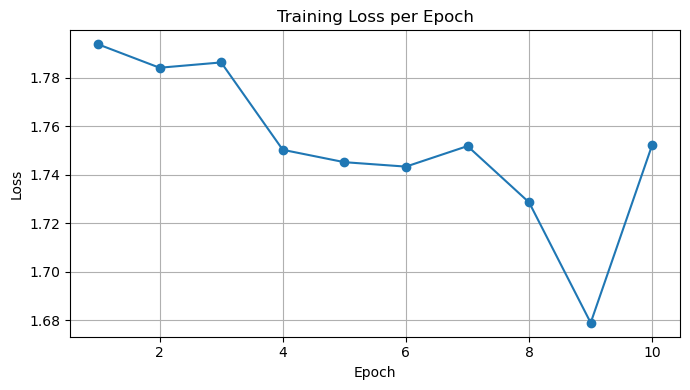

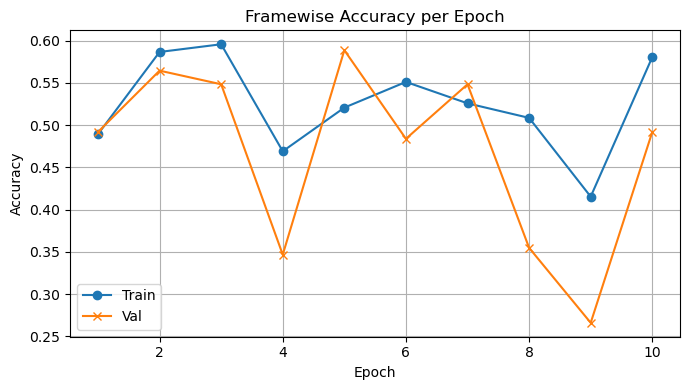

In [19]:
# Track + visualize training progress (loss & accuracy)

import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

def framewise_accuracy(model, loader, device, ignore_index=-100):
    model.eval()
    yt, yp = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb).argmax(dim=-1)            # [B, T]
            yb = yb.cpu().numpy().reshape(-1)          # [B*T]
            pd = pred.cpu().numpy().reshape(-1)        # [B*T]
            mask = (yb != ignore_index)                # drop padding frames
            yt.extend(yb[mask]); yp.extend(pd[mask])
    return accuracy_score(yt, yp) if yt else 0.0

def train_loop(model, train_loader, val_loader, device, epochs=10, lr=1e-4, class_weights=None):
    model.to(device)
    if class_weights is not None:
        cw = torch.tensor(class_weights, dtype=torch.float32, device=device)
        loss_fn = nn.CrossEntropyLoss(weight=cw, ignore_index=-100)
    else:
        loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
    opt = optim.Adam(model.parameters(), lr=lr)

    history = {"loss": [], "train_acc": [], "val_acc": []}

    for ep in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                                        # [B, T, C]
            loss = loss_fn(logits.reshape(-1, logits.size(-1)), yb.view(-1))
            opt.zero_grad(); loss.backward(); opt.step()
            running += loss.item()

        avg_loss = running / max(1, len(train_loader))
        train_acc = framewise_accuracy(model, train_loader, device)   # uses eval mode internally
        val_acc   = framewise_accuracy(model, val_loader, device)

        history["loss"].append(avg_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        log(f"[Epoch {ep+1:03d}] loss={avg_loss:.4f}  train_acc={train_acc:.4f}  val_acc={val_acc:.4f}")

    return history

In [7]:

def softmax_torch(x, dim=-1): 
    return torch.softmax(x, dim=dim)

def enforce_N_exclusivity(frame_prob: np.ndarray, n_idx: int) -> np.ndarray:
    """Zero N where any non-N has higher prob."""
    out = frame_prob.copy()
    non_n = [i for i in range(frame_prob.shape[1]) if i != n_idx]
    for t in range(out.shape[0]):
        if np.max(out[t, non_n]) > out[t, n_idx]:
            out[t, n_idx] = 0.0
    return out

def sliding_predict_one(model, poses_full: np.ndarray, device, window=64, stride=32, threshold=0.5):
    model.eval()
    T = poses_full.shape[0]; C = len(LABEL_MAP)
    accum = np.zeros((T,C), np.float32); counts = np.zeros(T, np.int32)
    with torch.no_grad():
        s = 0
        while s < T:
            e = min(s + window, T)
            xw = torch.tensor(poses_full[s:e], dtype=torch.float32, device=device).unsqueeze(0)
            probs = softmax_torch(model(xw), dim=-1).squeeze(0).cpu().numpy()  # [L,C]
            accum[s:e] += probs; counts[s:e] += 1
            if e == T: break
            s += stride
    frame_prob = accum / np.maximum(counts[:,None], 1)
    n_idx = LABEL_MAP["N"]
    frame_prob = enforce_N_exclusivity(frame_prob, n_idx)
    mask = frame_prob >= threshold
    # hard rule: if any non-N active at frame, disable N
    any_non_n = np.any(mask[:, [i for i in range(C) if i != n_idx]], axis=1)
    mask[any_non_n, n_idx] = False
    # if nothing active, allow N if N is argmax
    off_all = ~np.any(mask, axis=1)
    n_best = np.argmax(frame_prob, axis=1) == n_idx
    mask[off_all & n_best, n_idx] = True
    return frame_prob, mask

def segments_from_mask(mask: np.ndarray):
    T, C = mask.shape; out = {}
    for c in range(C):
        out[INV_LABEL_MAP[c]] = contiguous_segments_from_mask(mask[:,c])
    return out

def pretty_segments(seg_dict):
    def fmt(lst): 
        return ", ".join([f"{s+1}-{e+1}" for (s,e) in lst]) if lst else ""
    lines = []
    for name in LABEL_MAP.keys():
        s = fmt(seg_dict.get(name, []))
        if s:
            lines.append(f"{name}: {s}")
    return "\n".join(lines) if lines else "(no segments)"


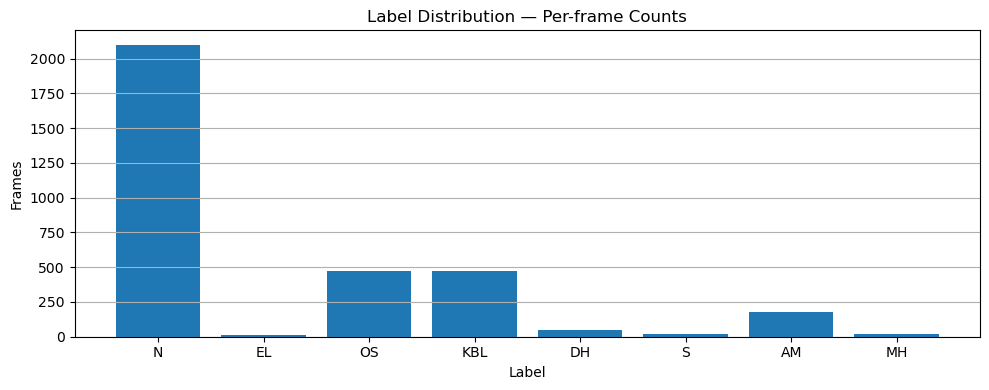

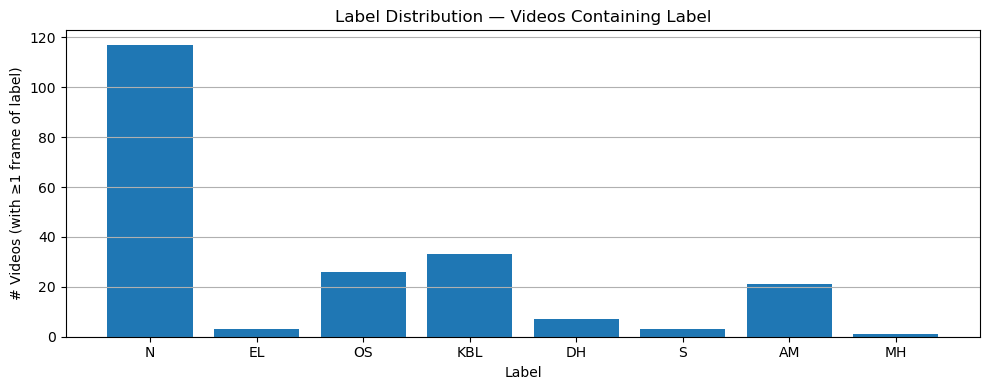

Per-frame counts:
  N: 2098
  EL: 13
  OS: 470
  KBL: 474
  DH: 46
  S: 18
  AM: 178
  MH: 22

Per-video presence:
  N: 117 video(s)
  EL: 3 video(s)
  OS: 26 video(s)
  KBL: 33 video(s)
  DH: 7 video(s)
  S: 3 video(s)
  AM: 21 video(s)
  MH: 1 video(s)


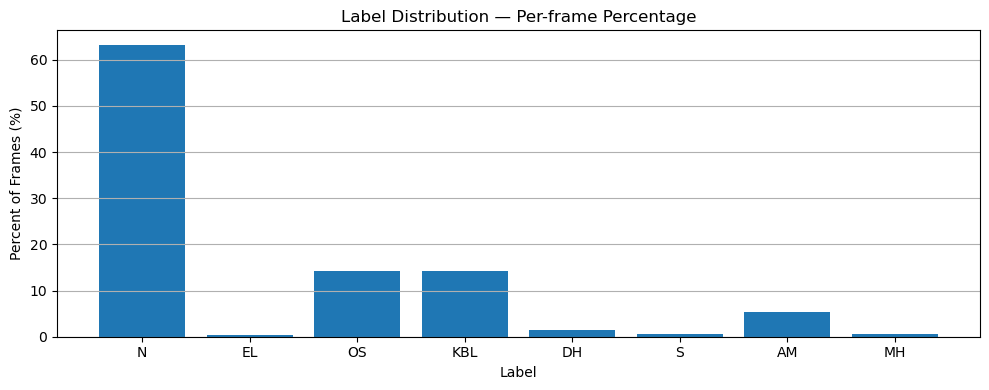

In [18]:
# Visualize label distribution (per-frame and per-video)
import numpy as np
import matplotlib.pyplot as plt

# --- collect stats ---
num_classes = len(LABEL_MAP)
labels_order = list(LABEL_MAP.keys())                    # keep your defined order
idx_order = [LABEL_MAP[k] for k in labels_order]

# Per-frame counts
frame_counts = np.zeros(num_classes, dtype=np.int64)
# Per-video presence (boolean: does this video contain label c at least once?)
video_presence = np.zeros(num_classes, dtype=np.int64)

for s in dataset.samples:
    y = s["labels_full"] if "labels_full" in s else s["y_train"]
    y = np.asarray(y, dtype=np.int64)
    valid = y[y != -100]
    # frame counts
    for v in valid:
        frame_counts[int(v)] += 1
    # video presence
    if valid.size > 0:
        uniq = np.unique(valid)
        for v in uniq:
            video_presence[int(v)] += 1

# Reorder to match LABEL_MAP key order
frame_counts = frame_counts[idx_order]
video_presence = video_presence[idx_order]

# --- Plot: per-frame counts ---
plt.figure(figsize=(10, 4))
plt.bar(labels_order, frame_counts)
plt.title("Label Distribution — Per-frame Counts")
plt.xlabel("Label")
plt.ylabel("Frames")
plt.xticks(rotation=0)
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

# --- Plot: per-video presence ---
plt.figure(figsize=(10, 4))
plt.bar(labels_order, video_presence)
plt.title("Label Distribution — Videos Containing Label")
plt.xlabel("Label")
plt.ylabel("# Videos (with ≥1 frame of label)")
plt.xticks(rotation=0)
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

# (Optional) quick text summary
print("Per-frame counts:")
for lab, cnt in zip(labels_order, frame_counts):
    print(f"  {lab}: {cnt}")

print("\nPer-video presence:")
for lab, cnt in zip(labels_order, video_presence):
    print(f"  {lab}: {cnt} video(s)")


total_frames = frame_counts.sum()
frame_pct = (frame_counts / total_frames * 100.0) if total_frames > 0 else np.zeros_like(frame_counts, dtype=float)

plt.figure(figsize=(10, 4))
plt.bar(labels_order, frame_pct)
plt.title("Label Distribution — Per-frame Percentage")
plt.xlabel("Label")
plt.ylabel("Percent of Frames (%)")
plt.xticks(rotation=0)
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

In [10]:

# Choose source: prefer S3_PATH if set, otherwise SM_CHANNEL_TRAINING/local path
DATA_SOURCE = S3_PATH if S3_PATH else LOCAL_DATA
print("DATA_SOURCE:", DATA_SOURCE)

dataset = PoseDataset(DATA_SOURCE, max_len=MAX_FRAMES, debug=True)
dataset.analyze_data()
class_counts, class_weights = dataset.compute_class_weights()
print("Class counts :", class_counts)
print("Class weights:", class_weights)

N = len(dataset)
if N < 3:
    print("[WARN] Very small dataset; using 60/20/20 split.")
    tr = max(1, int(0.6*N)); va = max(0, int(0.2*N)); te = max(0, N-tr-va)
else:
    tr = int(TRAIN_SPLIT * N); va = int(VAL_SPLIT * N); te = N - tr - va

g = torch.Generator().manual_seed(42)
idx = torch.randperm(N, generator=g).tolist()
train_idx = idx[:tr]; val_idx = idx[tr:tr+va]; test_idx = idx[tr+va:]

train_loader = DataLoader(Subset(dataset, train_idx), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(Subset(dataset, val_idx),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(Subset(dataset, test_idx),  batch_size=BATCH_SIZE, shuffle=False)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


DATA_SOURCE: s3://sagemaker-posedata/
[INFO] Listing S3: s3://sagemaker-posedata/
[INFO] Found 224 JSON files.
[DEBUG] First files: sagemaker-posedata/1-elaine-KBL-2-training.json, sagemaker-posedata/1-elaine-KBL-3-training.json, sagemaker-posedata/1-elaine-KBL-4-training.json, sagemaker-posedata/1-elaine-N-1-training.json, sagemaker-posedata/1-elaine-N-2-training.json
[DEBUG] sagemaker-posedata/1-elaine-KBL-2-training.json -> T=94, train_view=(300, 51)
[DEBUG] sagemaker-posedata/1-elaine-KBL-3-training.json -> T=32, train_view=(300, 51)
[INFO] Total videos: 224
[INFO] Training tensor shape: (300, 51)
[INFO] Label presence across videos: N:117, EL:3, OS:26, KBL:33, DH:7, S:3, AM:21, MH:1
Class counts : [759   9 150 176  29  15 102   5]
Class weights: [ 0.20503953 17.29166667  1.0375      0.88423295  5.36637931 10.375
  1.52573529 31.125     ]
Device: cpu


In [11]:

model = PoseViTSegmentClassifier(num_classes=len(LABEL_MAP), hidden_dim=HIDDEN_DIM, max_frames=MAX_FRAMES)
# === Train and capture history ===
history = train_loop(model, train_loader, val_loader, device, epochs=EPOCHS, lr=LR, class_weights=class_weights)

# === Plot: Loss ===
plt.figure(figsize=(7,4))
plt.plot(range(1, len(history["loss"])+1), history["loss"], marker='o')
plt.title("Training Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

# === Plot: Accuracy (Train & Val) ===
plt.figure(figsize=(7,4))
plt.plot(range(1, len(history["train_acc"])+1), history["train_acc"], marker='o', label="Train")
plt.plot(range(1, len(history["val_acc"])+1),   history["val_acc"],   marker='x', label="Val")
plt.title("Framewise Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
print("Framewise test (padded view):", framewise_accuracy(model, test_loader, device))


/opt/conda/lib/python3.12/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


[Epoch 001] loss=2.0026 val_acc=0.5645
[Epoch 002] loss=1.8641 val_acc=0.5000
[Epoch 003] loss=1.8454 val_acc=0.5484
[Epoch 004] loss=1.8454 val_acc=0.5242
[Epoch 005] loss=1.8298 val_acc=0.5645
[Epoch 006] loss=1.7981 val_acc=0.5484
[Epoch 007] loss=1.8218 val_acc=0.5484
[Epoch 008] loss=1.8007 val_acc=0.5484
[Epoch 009] loss=1.7655 val_acc=0.5484
[Epoch 010] loss=1.7765 val_acc=0.5887
Framewise test (padded view): 0.7611940298507462


In [12]:

# Segment-level evaluation (IoU-based) + sliding-window framewise accuracy
per_label = {k: {"tp":0,"fp":0,"fn":0} for k in LABEL_MAP.keys()}
yt, yp = [], []

for i in test_idx:
    s = dataset.samples[i]
    poses = s["poses_full"]; labels = s["labels_full"].copy(); T = s["T"]
    frame_prob, mask = sliding_predict_one(model, poses, device, window=WINDOW, stride=STRIDE, threshold=THRESHOLD)
    pred_fw = np.argmax(frame_prob, axis=1)
    m = (labels != -100)
    yt.extend(labels[m]); yp.extend(pred_fw[m])

    # build GT mask/segments
    gt_mask = np.zeros_like(mask, dtype=bool)
    for t in range(T):
        if labels[t] != -100:
            gt_mask[t, labels[t]] = True
    gt_segs = segments_from_mask(gt_mask)
    pr_segs = segments_from_mask(mask)

    for name in LABEL_MAP.keys():
        tp,fp,fn = match_segments(pr_segs.get(name,[]), gt_segs.get(name,[]), iou_thresh=IOU_THRESH)
        d = per_label[name]; d["tp"]+=tp; d["fp"]+=fp; d["fn"]+=fn

slide_acc = accuracy_score(yt, yp) if yt else 0.0
print(f"[Sliding-window] Framewise accuracy: {slide_acc:.4f}")

def prf(tp,fp,fn):
    p = tp/(tp+fp) if (tp+fp)>0 else 0.0
    r = tp/(tp+fn) if (tp+fn)>0 else 0.0
    f = 2*p*r/(p+r) if (p+r)>0 else 0.0
    return p,r,f

micro_tp = sum(d["tp"] for d in per_label.values())
micro_fp = sum(d["fp"] for d in per_label.values())
micro_fn = sum(d["fn"] for d in per_label.values())
mp, mr, mf1 = prf(micro_tp, micro_fp, micro_fn)
print(f"[Segment micro] P={mp:.3f} R={mr:.3f} F1={mf1:.3f} (tp={micro_tp}, fp={micro_fp}, fn={micro_fn})")

print("Per-label segment metrics:")
for name, d in per_label.items():
    p,r,f1 = prf(d["tp"], d["fp"], d["fn"])
    print(f"  {name:>3}  P={p:.3f} R={r:.3f} F1={f1:.3f} (tp={d['tp']}, fp={d['fp']}, fn={d['fn']})")


[Sliding-window] Framewise accuracy: 0.7296
[Segment micro] P=0.000 R=0.000 F1=0.000 (tp=0, fp=23, fn=22)
Per-label segment metrics:
    N  P=0.000 R=0.000 F1=0.000 (tp=0, fp=23, fn=17)
   EL  P=0.000 R=0.000 F1=0.000 (tp=0, fp=0, fn=1)
   OS  P=0.000 R=0.000 F1=0.000 (tp=0, fp=0, fn=1)
  KBL  P=0.000 R=0.000 F1=0.000 (tp=0, fp=0, fn=3)
   DH  P=0.000 R=0.000 F1=0.000 (tp=0, fp=0, fn=0)
    S  P=0.000 R=0.000 F1=0.000 (tp=0, fp=0, fn=0)
   AM  P=0.000 R=0.000 F1=0.000 (tp=0, fp=0, fn=0)
   MH  P=0.000 R=0.000 F1=0.000 (tp=0, fp=0, fn=0)


In [16]:
# Predict ALL test videos and report accuracies (sliding-window)
from collections import defaultdict

PRINT_SEGMENTS = True   # set False if you only want the accuracy numbers

results = []
all_true, all_pred = [], []

for i in test_idx:
    s = dataset.samples[i]
    poses = s["poses_full"]
    labels = s["labels_full"].copy()
    T = s["T"]
    fname = os.path.basename(s["fname"])

    # Sliding-window inference
    frame_prob, mask = sliding_predict_one(
        model, poses, device, window=WINDOW, stride=STRIDE, threshold=THRESHOLD
    )
    pred_fw = np.argmax(frame_prob, axis=1)

    # Framewise accuracy for this video (ignore -100 padding labels)
    valid = (labels != -100)
    vid_true = labels[valid]
    vid_pred = pred_fw[valid]
    all_true.extend(vid_true)
    all_pred.extend(vid_pred)

    vid_acc = (vid_true == vid_pred).mean() if vid_true.size > 0 else np.nan

    # Optional: human-readable segments
    segs = segments_from_mask(mask)
    seg_text = pretty_segments(segs) if PRINT_SEGMENTS else ""

    results.append({
        "video": fname,
        "frames_total": int(T),
        "frames_eval": int(valid.sum()),
        "accuracy": float(vid_acc),
        "segments": seg_text
    })

# Overall test accuracy (sliding-window, framewise)
overall_accuracy = (np.array(all_true) == np.array(all_pred)).mean() if len(all_true) else 0.0

# Print summary
print(f"[TEST] Sliding-window framewise accuracy (overall): {overall_accuracy:.4f}\n")
print("Per-video accuracy:")
for r in results:
    print(f"  {r['video']}: acc={r['accuracy']:.4f}  (eval_frames={r['frames_eval']}/{r['frames_total']})")
    if PRINT_SEGMENTS and r["segments"]:
        print("    Segments:")
        for line in r["segments"].splitlines():
            print("     ", line)
        print()

# If you want the results as a DataFrame in the notebook:
try:
    import pandas as pd
    df = pd.DataFrame(results).sort_values("video")
    df
except Exception as e:
    pass


[TEST] Sliding-window framewise accuracy (overall): 0.7296

Per-video accuracy:
  9-elaine-N-1.json: acc=1.0000  (eval_frames=29/1764)
    Segments:
      N: 1-1764

  163-elaine-N.json: acc=1.0000  (eval_frames=7/430)
    Segments:
      N: 1-430

  134-elaine-KBL-1.json: acc=0.0000  (eval_frames=42/1269)
    Segments:
      N: 1-1269

  138-elaine-OS.json: acc=0.0000  (eval_frames=2/78)
    Segments:
      N: 1-78

  118-elaine-N.json: acc=1.0000  (eval_frames=6/198)
    Segments:
      N: 1-198

  156-elaine-EL.json: acc=0.0000  (eval_frames=9/587)
    Segments:
      N: 1-587

  82-扛麦郎-N-1.json: acc=1.0000  (eval_frames=21/1277)
    Segments:
      N: 1-1277

  9-elaine-N-5.json: acc=1.0000  (eval_frames=20/1242)
    Segments:
      N: 1-1242

  152-elaine-N.json: acc=1.0000  (eval_frames=21/1264)
    Segments:
      N: 1-1264

  136-elaine-N-2.json: acc=1.0000  (eval_frames=11/351)
    Segments:
      N: 1-351

  2-elaine-N-1.json: acc=1.0000  (eval_frames=2/83)
    Segments:
    

In [20]:

# Save model artifacts to SageMaker's expected path
os.makedirs(MODEL_DIR, exist_ok=True)
torch.save(model.state_dict(), os.path.join(MODEL_DIR, "model.pt"))
with open(os.path.join(MODEL_DIR, "label_map.json"), "w") as f:
    json.dump(LABEL_MAP, f)
print("Saved model to:", MODEL_DIR)


PermissionError: [Errno 13] Permission denied: '/opt/ml/model'